# PRODIGY_DS_04 — Twitter Sentiment Analysis & Visualization
**Prodigy InfoTech — Data Science Internship, Task 04**

Task: Analyze and visualize sentiment patterns in social media data to understand public opinion and attitudes towards specific topics or brands.

**Dataset:** Twitter Entity Sentiment Analysis — 74,682 tweets about 32 entities (games, consoles, corporate brands), each labeled Positive / Negative / Neutral / Irrelevant.

## 1. Import libraries & load data
The raw file has no header row, so column names are assigned manually.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

sns.set_style("whitegrid")
SENTIMENT_ORDER = ["Positive", "Neutral", "Negative"]
SENTIMENT_COLORS = {"Positive": "#4CAF50", "Neutral": "#9E9E9E", "Negative": "#E53935"}

!wget -q -O twitter_training.csv https://raw.githubusercontent.com/kindo-tk/PRODIGY_DS_04/main/twitter_training.csv
df = pd.read_csv("twitter_training.csv", header=None, names=["tweet_id", "entity", "sentiment", "tweet"])
print(df.shape)
df.head()

(74682, 4)


,tweet_id,entity,sentiment,tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


## 2. Inspect the raw data

In [2]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSentiment counts:\n", df["sentiment"].value_counts())
print("\nNumber of entities:", df["entity"].nunique())

Missing values:
 tweet_id       0
entity         0
sentiment      0
tweet        686
dtype: int64

Duplicate rows: 2700

Sentiment counts:
 sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64

Number of entities: 32


## 3. Data cleaning
- Drop tweets with missing text
- Drop exact duplicate rows (genuine duplicates, since `tweet_id` exists)
- Merge **Irrelevant → Neutral**, following the dataset's own documentation
- Clean text for word analysis (lowercase, remove URLs/mentions/non-letters)
- Tag each entity as **Gaming** or **Corporate Brand** (my own grouping)

In [3]:
df = df.dropna(subset=["tweet"])
df = df.drop_duplicates()
df["sentiment"] = df["sentiment"].replace("Irrelevant", "Neutral")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["clean_tweet"] = df["tweet"].apply(clean_text)
df = df[df["clean_tweet"].str.len() > 0]

CORPORATE = {"Amazon", "Facebook", "Google", "HomeDepot", "Microsoft", "Nvidia", "Verizon", "johnson&johnson"}
df["category"] = df["entity"].apply(lambda e: "Corporate Brand" if e in CORPORATE else "Gaming")

print("Clean shape:", df.shape)
print(df["sentiment"].value_counts())

Clean shape: (71315, 6)
sentiment
Neutral     30066
Negative    21605
Positive    19644
Name: count, dtype: int64


## 4. Overall sentiment distribution

sentiment
Positive    27.5
Neutral     42.2
Negative    30.3
Name: count, dtype: float64


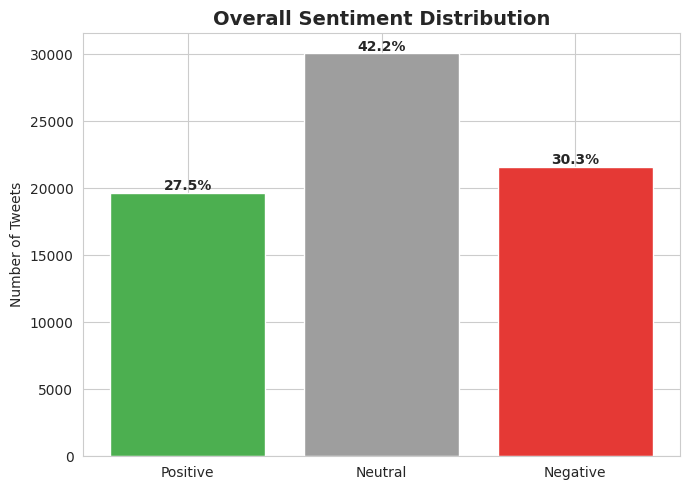

In [4]:
overall = df["sentiment"].value_counts().reindex(SENTIMENT_ORDER)
overall_pct = (overall / overall.sum() * 100).round(1)
print(overall_pct)

plt.figure(figsize=(7, 5))
bars = plt.bar(overall.index, overall.values, color=[SENTIMENT_COLORS[s] for s in overall.index])
for bar, pct in zip(bars, overall_pct):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200, f"{pct}%", ha="center", fontweight="bold")
plt.title("Overall Sentiment Distribution", fontsize=14, fontweight="bold")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.savefig("overall_sentiment_distribution.png", dpi=150)
plt.show()

## 5. Sentiment breakdown by entity (100% stacked)

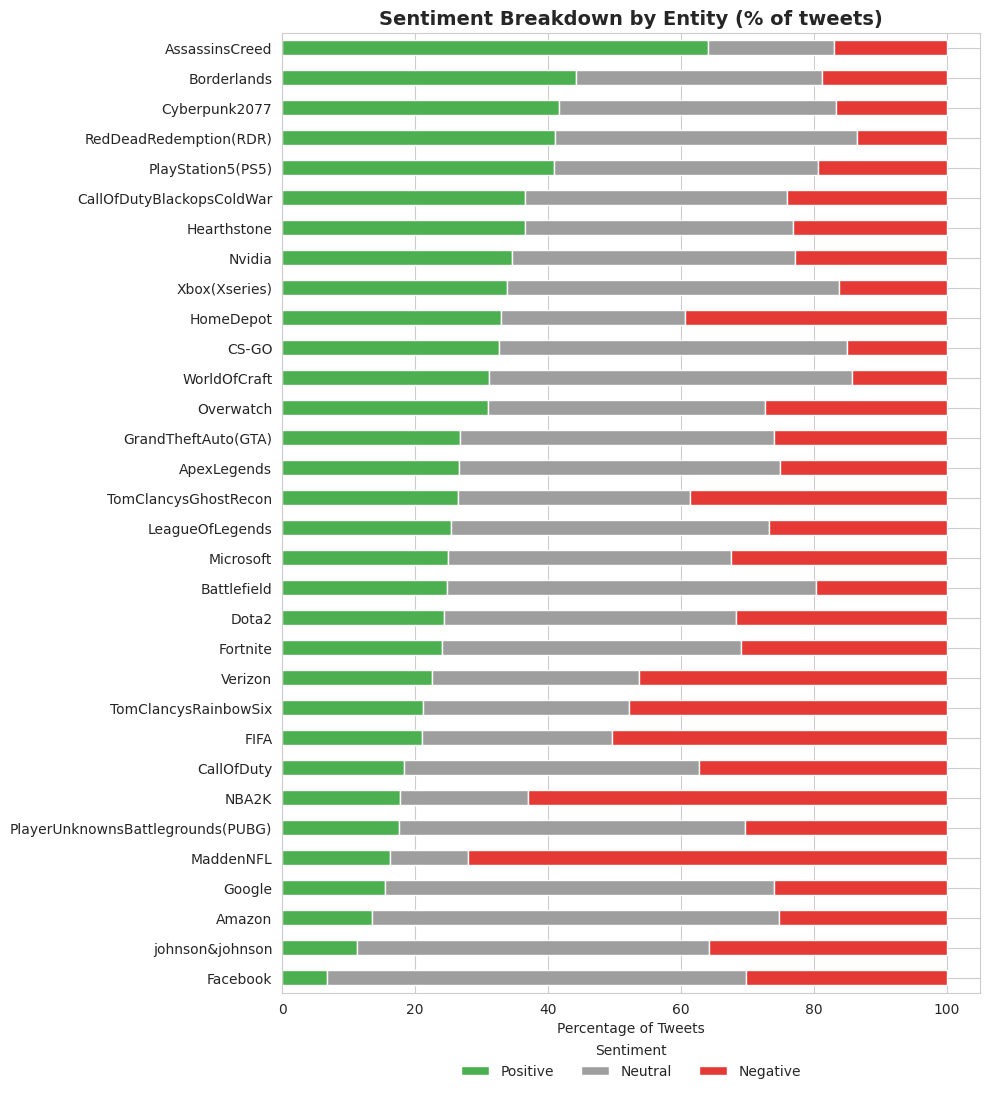

In [5]:
ct = pd.crosstab(df["entity"], df["sentiment"], normalize="index")[SENTIMENT_ORDER] * 100
ct = ct.sort_values("Positive")

ct.plot(kind="barh", stacked=True, figsize=(10, 11), color=[SENTIMENT_COLORS[s] for s in SENTIMENT_ORDER])
plt.title("Sentiment Breakdown by Entity (% of tweets)", fontsize=14, fontweight="bold")
plt.xlabel("Percentage of Tweets"); plt.ylabel("")
plt.legend(title="Sentiment", loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig("sentiment_by_entity.png", dpi=150)
plt.show()

## 6. Most positively vs. most negatively discussed entities

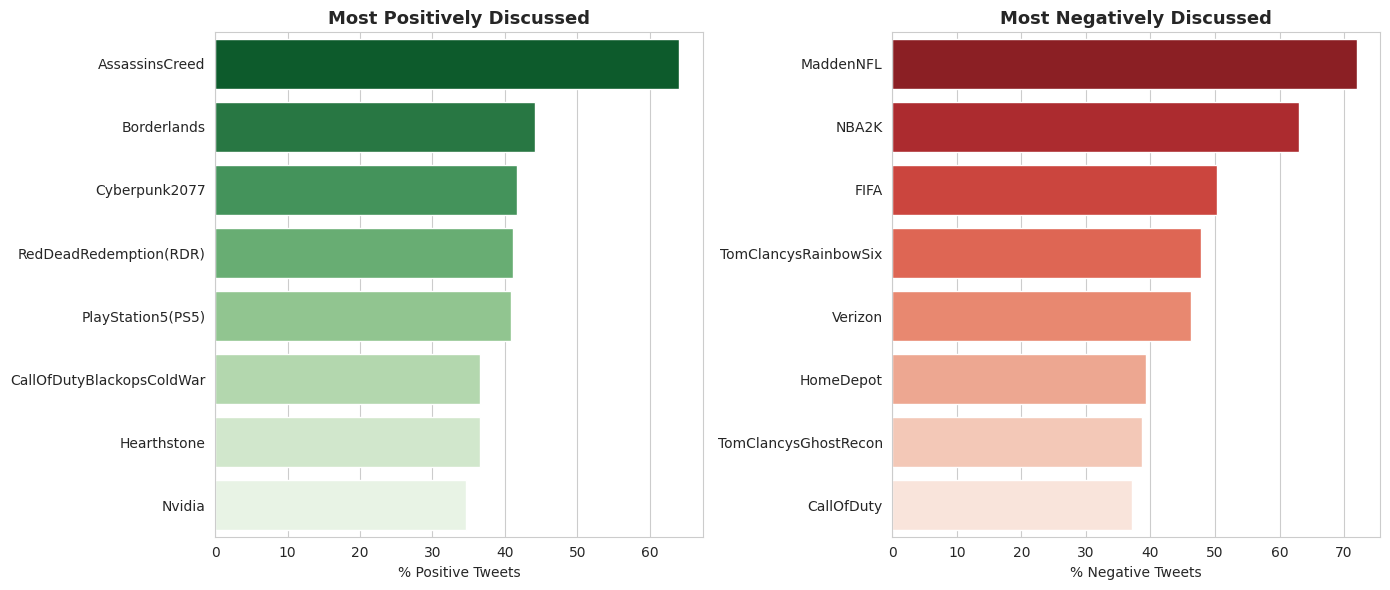

entity
AssassinsCreed               64.1
Borderlands                  44.2
Cyberpunk2077                41.6
RedDeadRedemption(RDR)       41.1
PlayStation5(PS5)            40.9
CallOfDutyBlackopsColdWar    36.6
Hearthstone                  36.5
Nvidia                       34.6
Name: Positive, dtype: float64

entity
MaddenNFL               72.0
NBA2K                   63.1
FIFA                    50.3
TomClancysRainbowSix    47.9
Verizon                 46.2
HomeDepot               39.3
TomClancysGhostRecon    38.6
CallOfDuty              37.2
Name: Negative, dtype: float64


In [6]:
top_pos = ct["Positive"].sort_values(ascending=False).head(8)
top_neg = ct["Negative"].sort_values(ascending=False).head(8)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=top_pos.values, y=top_pos.index, hue=top_pos.index, palette="Greens_r", legend=False, ax=axes[0])
axes[0].set_title("Most Positively Discussed", fontsize=13, fontweight="bold")
axes[0].set_xlabel("% Positive Tweets"); axes[0].set_ylabel("")
sns.barplot(x=top_neg.values, y=top_neg.index, hue=top_neg.index, palette="Reds_r", legend=False, ax=axes[1])
axes[1].set_title("Most Negatively Discussed", fontsize=13, fontweight="bold")
axes[1].set_xlabel("% Negative Tweets"); axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("top_positive_negative_entities.png", dpi=150)
plt.show()

print(top_pos.round(1)); print(); print(top_neg.round(1))

## 7. Sentiment heatmap

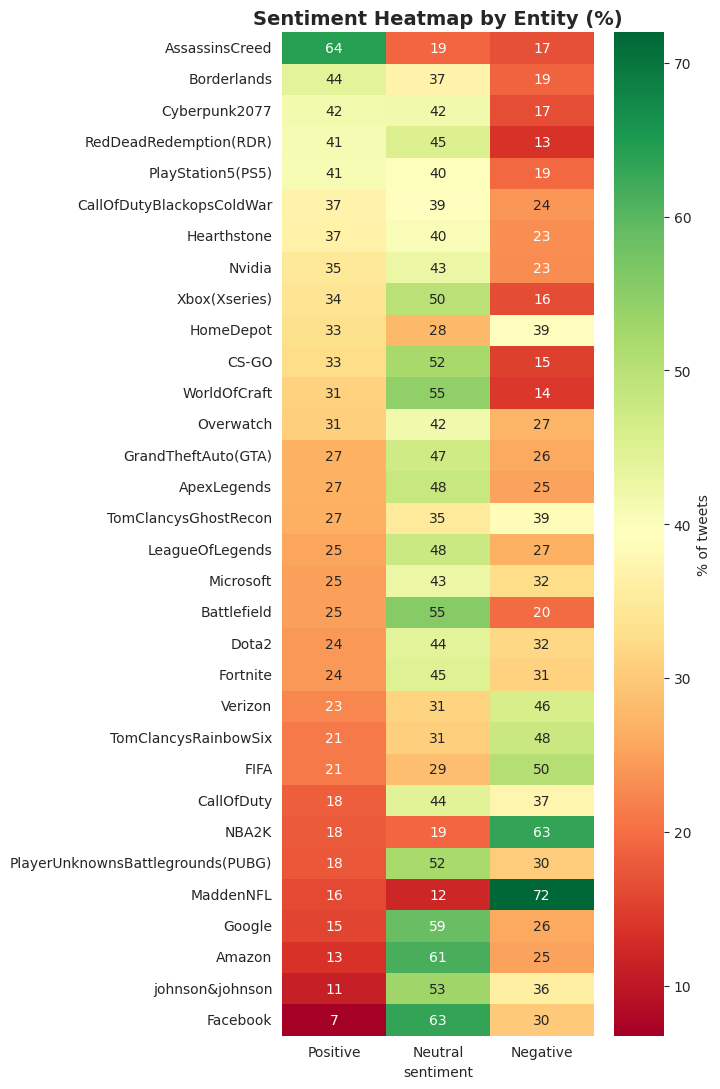

In [7]:
plt.figure(figsize=(7, 11))
sns.heatmap(ct.sort_values("Positive", ascending=False), annot=True, fmt=".0f", cmap="RdYlGn", cbar_kws={"label": "% of tweets"})
plt.title("Sentiment Heatmap by Entity (%)", fontsize=14, fontweight="bold")
plt.ylabel("")
plt.tight_layout()
plt.savefig("sentiment_heatmap.png", dpi=150)
plt.show()

## 8. Gaming vs. corporate brands

sentiment        Positive  Neutral  Negative
category                                    
Corporate Brand      20.2     47.5      32.3
Gaming               30.0     40.4      29.6


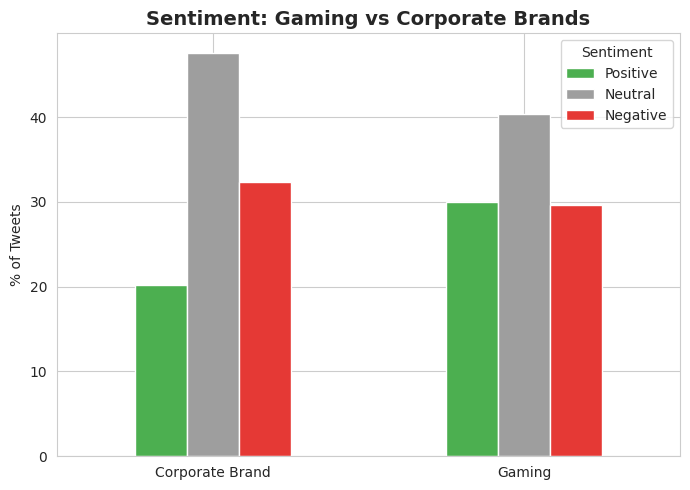

In [8]:
cat_ct = pd.crosstab(df["category"], df["sentiment"], normalize="index")[SENTIMENT_ORDER] * 100
print(cat_ct.round(1))

cat_ct.plot(kind="bar", figsize=(7, 5), color=[SENTIMENT_COLORS[s] for s in SENTIMENT_ORDER])
plt.title("Sentiment: Gaming vs Corporate Brands", fontsize=14, fontweight="bold")
plt.ylabel("% of Tweets"); plt.xlabel(""); plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.savefig("gaming_vs_corporate.png", dpi=150)
plt.show()

## 9. Most common words: positive vs. negative tweets
Entity names, URL fragments (`pic.twitter.com`), generic words, one repeated streamer handle and profanity are excluded so the chart shows real opinion words (presentation choice only — sentiment labels are untouched).

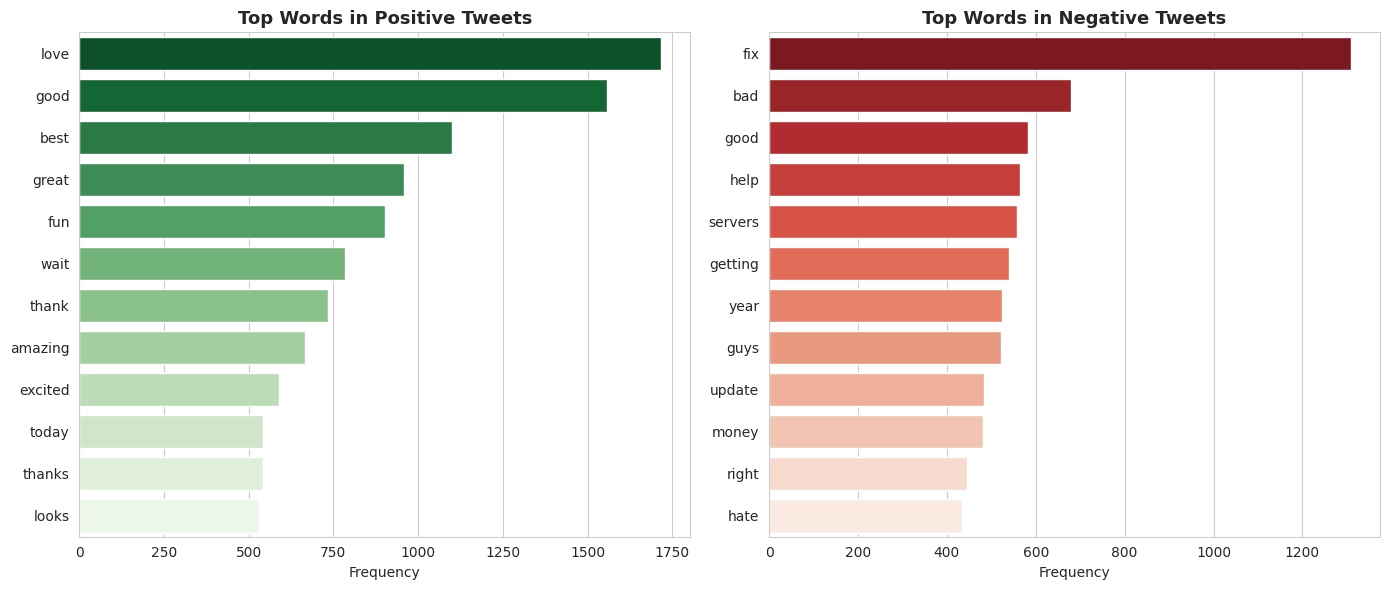

In [9]:
extra_stops = {"im", "ive", "dont", "didnt", "doesnt", "just", "like", "get", "got", "going", "know",
               "really", "one", "make", "think", "want", "thing", "ve", "don", "didn", "ll", "re",
               "amp", "u", "rt", "https", "co"}
url_noise = {"com", "pic", "twitter", "unk"}
handle_noise = {"rhandlerr"}
generic_words = {"game", "games", "play", "playing", "played", "time", "new", "people"}
profanity = {"shit", "fuck", "fucking", "fucked", "damn", "crap", "ass", "bitch", "hell", "wtf"}
stops = list(ENGLISH_STOP_WORDS.union(extra_stops, url_noise, handle_noise, generic_words, profanity))

entity_words = set()
for e in df["entity"].unique():
    spaced = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", e)
    entity_words.update(re.findall(r"[a-z]+", spaced.lower()))
entity_words.update({"home", "depot", "creed", "assassins"})
stops = stops + list(entity_words)

def top_words(sentiment, n=12):
    texts = df.loc[df["sentiment"] == sentiment, "clean_tweet"]
    vec = CountVectorizer(stop_words=stops, min_df=5)
    counts = vec.fit_transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=vec.get_feature_names_out()).sort_values(ascending=False).head(n)

pos_words = top_words("Positive")
neg_words = top_words("Negative")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=pos_words.values, y=pos_words.index, hue=pos_words.index, palette="Greens_r", legend=False, ax=axes[0])
axes[0].set_title("Top Words in Positive Tweets", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Frequency"); axes[0].set_ylabel("")
sns.barplot(x=neg_words.values, y=neg_words.index, hue=neg_words.index, palette="Reds_r", legend=False, ax=axes[1])
axes[1].set_title("Top Words in Negative Tweets", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Frequency"); axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("top_words_by_sentiment.png", dpi=150)
plt.show()

## 10. Key findings
- **Overall:** Neutral 42.2%, Negative 30.3%, Positive 27.5% — negative tweets outnumber positive ones.
- **Most positive:** Assassin's Creed (64.1%), Borderlands (44.2%), Cyberpunk 2077 (41.6%).
- **Most negative:** Madden NFL (72.0%), NBA 2K (63.1%), FIFA (50.3%) — the three sports titles top the list.
- **Gaming vs. corporate brands:** gaming draws more positive sentiment (30.0% vs 20.2%); corporate brands skew more neutral.
- **Language:** negative tweets feature *fix, bad, help, servers, update, money* — complaints often center on bugs, servers, updates and pricing.

*Limitation:* simple word counts with no negation handling, which is why "good" also shows up in negative tweets.

---
*Part of the Data Science Internship @ Prodigy InfoTech (Oct 2026)* #ProdigyInfoTech